Начинаем работу: 1. Генерация данных...
CSV-файлы успешно сгенерированы и сохранены.

2. Выполнение SQL-запроса...
SQL-слияние завершено. Итоговая таблица (master_sales_data.csv) создана.

3. Расчет бизнес-метрик (Pandas)...

--- ТОП-3 КЛИЕНТА ПО ВЫРУЧКЕ ---
client_name
Петров К.М. (РегионГаз)        86,503,000 руб.
Лебедев Т.А. (АгроКомплекс)    78,697,000 руб.
Иванов А.А. (ГазПромСтрой)     77,968,500 руб.
Name: revenue, dtype: object

--- ПРОДАЖИ ОБОРУДОВАНИЯ (ШТ.) ---
device_name
Модем GSM/GPRS            3044
Счетчик импульсов СИ-2    2764
Датчик давления ДД-10     2325
Шкаф телеметрии ШРП       2294
Блок телеметрии БП-100    2268
Name: quantity, dtype: int64

4. График сохранен как 'sales_trend.png'. Проект завершен!


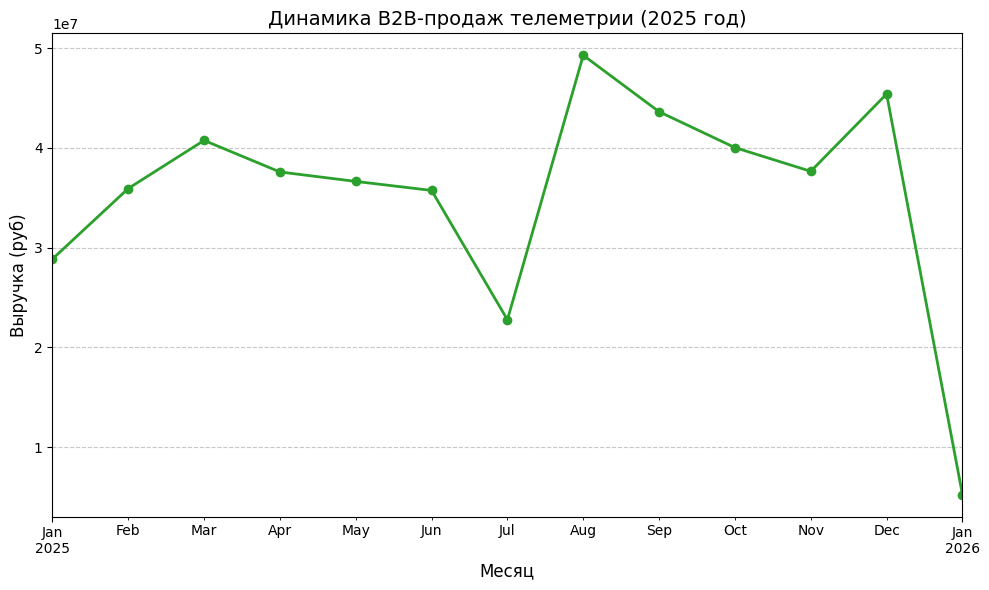

In [1]:
import pandas as pd
import sqlite3
import random
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

print("Начинаем работу: 1. Генерация данных...")

# --- ШАГ 1: ГЕНЕРАЦИЯ СЫРЫХ ДАННЫХ ---
# 1. Справочник клиентов (известны ФИО и привязанные к ним номера)
clients_data = {
    'client_id': [101, 102, 103, 104, 105, 106, 107],
    'fio': ['Иванов А.А. (ГазПромСтрой)', 'Смирнов В.И. (ТеплоСеть)',
            'Петров К.М. (РегионГаз)', 'Соколова А.В. (ПромАвтоматика)',
            'Морозов Д.С. (ИнжТех)', 'Волков Н.Н. (УчетСервис)', 'Лебедев Т.А. (АгроКомплекс)'],
    'region': ['Москва', 'Вологодская обл.', 'Рязанская обл.',
               'Владимирская обл.', 'Тамбовская обл.', 'Московская обл.', 'Москва']
}
df_clients = pd.DataFrame(clients_data)

# 2. Каталог оборудования (телеметрия)
catalog_data = {
    'device_id': ['T-001', 'T-002', 'T-003', 'T-004', 'T-005'],
    'device_name': ['Блок телеметрии БП-100', 'Счетчик импульсов СИ-2',
                    'Модем GSM/GPRS', 'Датчик давления ДД-10', 'Шкаф телеметрии ШРП'],
    'price': [45000, 12000, 8500, 5000, 125000]
}
df_catalog = pd.DataFrame(catalog_data)

# 3. Транзакции B2B-продаж (известны только номера, но не ФИО)
random.seed(42)
transactions = []
start_date = datetime(2025, 1, 1)

for i in range(500): # Генерируем 500 продаж
    t_date = start_date + timedelta(days=random.randint(0, 365))
    transactions.append({
        'transaction_id': f"TRX-{1000+i}",
        'date': t_date.strftime('%Y-%m-%d'),
        'client_id': random.choice(clients_data['client_id']),
        'device_id': random.choice(catalog_data['device_id']),
        'quantity': random.randint(1, 50) # Оптовые партии
    })
df_transactions = pd.DataFrame(transactions)

# Сохраняем сырые данные для GitHub
df_transactions.to_csv('transactions.csv', index=False)
df_clients.to_csv('clients.csv', index=False)
df_catalog.to_csv('catalog.csv', index=False)
print("CSV-файлы успешно сгенерированы и сохранены.")


# --- ШАГ 2: SQL (СЛИЯНИЕ И ОЧИСТКА ВМЕСТО ВПР) ---
print("\n2. Выполнение SQL-запроса...")
# Создаем временную SQL-базу в оперативной памяти
conn = sqlite3.connect(':memory:')
df_transactions.to_sql('transactions', conn, index=False)
df_clients.to_sql('clients', conn, index=False)
df_catalog.to_sql('catalog', conn, index=False)

# SQL-запрос для объединения таблиц и расчета выручки
sql_query = """
SELECT
    t.date,
    t.transaction_id,
    c.fio AS client_name,
    c.region,
    cat.device_name,
    t.quantity,
    cat.price,
    (t.quantity * cat.price) AS revenue
FROM transactions t
LEFT JOIN clients c ON t.client_id = c.client_id
LEFT JOIN catalog cat ON t.device_id = cat.device_id
ORDER BY t.date;
"""
# Загружаем результат SQL-запроса обратно в Pandas
df_master = pd.read_sql_query(sql_query, conn)
df_master.to_csv('master_sales_data.csv', index=False)
print("SQL-слияние завершено. Итоговая таблица (master_sales_data.csv) создана.")


# --- ШАГ 3: PANDAS АНАЛИТИКА ---
print("\n3. Расчет бизнес-метрик (Pandas)...")

# Топ-3 клиента по выручке
top_clients = df_master.groupby('client_name')['revenue'].sum().sort_values(ascending=False).head(3)
print("\n--- ТОП-3 КЛИЕНТА ПО ВЫРУЧКЕ ---")
print(top_clients.apply(lambda x: f"{x:,.0f} руб."))

# Самое продаваемое оборудование (в штуках)
top_devices = df_master.groupby('device_name')['quantity'].sum().sort_values(ascending=False)
print("\n--- ПРОДАЖИ ОБОРУДОВАНИЯ (ШТ.) ---")
print(top_devices)

# Динамика продаж по месяцам (для графика)
df_master['date'] = pd.to_datetime(df_master['date'])
monthly_revenue = df_master.set_index('date').resample('ME')['revenue'].sum()


# --- ШАГ 4: ВИЗУАЛИЗАЦИЯ И ЭКСПОРТ ---
plt.figure(figsize=(10, 6))
monthly_revenue.plot(kind='line', marker='o', color='#2ca02c', linewidth=2)
plt.title('Динамика B2B-продаж телеметрии (2025 год)', fontsize=14)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Выручка (руб)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('sales_trend.png', dpi=300)
print("\n4. График сохранен как 'sales_trend.png'. Проект завершен!")